# Deriving expenditure for each household

In [1]:
import pandas as pd
import os
import numpy as np

In [3]:
# Import dataframes with renamed columns 

# Path to your data folder (relative to the notebook location)
data_path = '/Users/gianjaeger/Desktop/Applied Machine Learning Project/Data'

# List of all file base names (same names used when pickling)
file_names = [
    "S08H_processing", "S09B_consfood", "S11A2_credit", "S11B_durables",
    "S07_enterprise", "S01_hhmembers", "S10E_otherexp", "S09C_consownfood",
    "S08A3_livestock", "S05E_services", "S06G_timeuse", "S11C_savings",
    "S09A1_consnonfood", "S08B2_equipment", "S10A_transfersout", "S06AB_occupation",
    "S08F_otheragric", "S08E_cropsmall", "S08A4_livestock", "S08A1_livestock",
    "S08G_inputs", "S08C_parcels", "S09A3_consnonfood", "S08A2_livestock",
    "S08B1_landtransactions", "S08D_croplarge", "S10B_transfersin", "S10D_schemes",
    "S09A2_consnonfood", "S06CDEF_jobs", "S05ABCD_housing", "S11A1_credit"
]

# Dynamically load each pickle file into a variable in the global namespace
for name in file_names:
    filepath = os.path.join(data_path, f"{name}.pkl")
    globals()[name] = pd.read_pickle(filepath)
    print(f"✅ Loaded {name}.pkl")


✅ Loaded S08H_processing.pkl
✅ Loaded S09B_consfood.pkl
✅ Loaded S11A2_credit.pkl
✅ Loaded S11B_durables.pkl
✅ Loaded S07_enterprise.pkl
✅ Loaded S01_hhmembers.pkl
✅ Loaded S10E_otherexp.pkl
✅ Loaded S09C_consownfood.pkl
✅ Loaded S08A3_livestock.pkl
✅ Loaded S05E_services.pkl
✅ Loaded S06G_timeuse.pkl
✅ Loaded S11C_savings.pkl
✅ Loaded S09A1_consnonfood.pkl
✅ Loaded S08B2_equipment.pkl
✅ Loaded S10A_transfersout.pkl
✅ Loaded S06AB_occupation.pkl
✅ Loaded S08F_otheragric.pkl
✅ Loaded S08E_cropsmall.pkl
✅ Loaded S08A4_livestock.pkl
✅ Loaded S08A1_livestock.pkl
✅ Loaded S08G_inputs.pkl
✅ Loaded S08C_parcels.pkl
✅ Loaded S09A3_consnonfood.pkl
✅ Loaded S08A2_livestock.pkl
✅ Loaded S08B1_landtransactions.pkl
✅ Loaded S08D_croplarge.pkl
✅ Loaded S10B_transfersin.pkl
✅ Loaded S10D_schemes.pkl
✅ Loaded S09A2_consnonfood.pkl
✅ Loaded S06CDEF_jobs.pkl
✅ Loaded S05ABCD_housing.pkl
✅ Loaded S11A1_credit.pkl


**Keep columns that are relevant to deriving expenditure and replace all values that were 999999 with nan**

In [4]:
# List of columns to keep
columns_to_keep = [
    'Household ID', 'Province', 'District (also stratum for SE calculation)', 'Urban/rural 2002', 
    'Quintile', 'Poverty status', 'Final weight of household', 'Cluster', 'Person ID Number', 'Sex', 
    'Relation with the head of household', 'Age (Years)', 'Age (Months)', 'Marital status', 
    'Place of birth', 'Nationality', 'PID of respondent', 'Total expenditures on school',
    'Amount paid on training fees last 12 months', 'Amount paid on other training costs last 12 months', 
    'Amount paid on fees for apprenticeship last 12 months', 
    'Amount paid on other costs for apprenticeship last 12 months', 'Amount paid for consultation by patient', 
    'Amount paid or to pay for examinations by patient', 
    'Amount paid or to pay for medical services by patient', 
    'Amount paid or to  be paid for medicines and medical supplies by patient', 
    'Amount paid for transport to and from medical establishment in the last 2 weeks', 
    'Amount paid for health care if not possible to itemize',
    'Amount paid or to pay for last vaccination'
]

# Keep only the specified columns
S01_hhmembers = S01_hhmembers[columns_to_keep]

# --------

#Remove all 99999999 values in these columns and convert "zeri o" to 0: 

# Columns to clean
columns_to_clean = [
    'Total expenditures on school',
    'Amount paid on training fees last 12 months', 
    'Amount paid on other training costs last 12 months', 
    'Amount paid on fees for apprenticeship last 12 months', 
    'Amount paid on other costs for apprenticeship last 12 months', 
    'Amount paid for consultation by patient', 
    'Amount paid or to pay for examinations by patient', 
    'Amount paid or to pay for medical services by patient', 
    'Amount paid or to  be paid for medicines and medical supplies by patient', 
    'Amount paid for transport to and from medical establishment in the last 2 weeks', 
    'Amount paid for health care if not possible to itemize',
    'Amount paid or to pay for last vaccination'
]

# Step-by-step cleaning
for col in columns_to_clean:
    # Replace string 'Zero' with numeric 0
    S01_hhmembers[col] = S01_hhmembers[col].replace('Zero', 0)
    
    # Convert everything in the column to numeric, coercing any non-numeric to NaN
    S01_hhmembers[col] = pd.to_numeric(S01_hhmembers[col], errors='coerce')
    
    # Replace placeholder 99999999 with NaN
    S01_hhmembers[col] = S01_hhmembers[col].replace(99999999, np.nan)

/var/folders/n5/_f2xjmkj39gb7s0th_6lyk9w0000gn/T/ipykernel_44152/3739218407.py:44: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  S01_hhmembers[col] = S01_hhmembers[col].replace('Zero', 0)
/var/folders/n5/_f2xjmkj39gb7s0th_6lyk9w0000gn/T/ipykernel_44152/3739218407.py:44: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  S01_hhmembers[col] = S01_hhmembers[col].replace('Zero', 0)
/var/folders/n5/_f2xjmkj39gb7s0th_6lyk9w0000gn/T/ipykernel_44152/3739218407.py:44: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future

In [5]:
# Keep only the second occurrence of 'PID of respondent'
cols = S01_hhmembers.columns
pid_indexes = [i for i, col in enumerate(cols) if col == 'PID of respondent']

# Drop all except the second
if len(pid_indexes) > 1:
    drop_indexes = pid_indexes[:1] + pid_indexes[2:]
    S01_hhmembers = S01_hhmembers.drop(S01_hhmembers.columns[drop_indexes], axis=1)

In [ ]:
columns_to_clean = [
    'Total expenditures on school',
    'Amount paid on training fees last 12 months', 
    'Amount paid on other training costs last 12 months', 
    'Amount paid on fees for apprenticeship last 12 months', 
    'Amount paid on other costs for apprenticeship last 12 months', 
    'Amount paid for consultation by patient', 
    'Amount paid or to pay for examinations by patient', 
    'Amount paid or to pay for medical services by patient', 
    'Amount paid or to  be paid for medicines and medical supplies by patient', 
    'Amount paid for transport to and from medical establishment in the last 2 weeks', 
    'Amount paid for health care if not possible to itemize',
    'Amount paid or to pay for last vaccination'
]

# Make a copy of the DataFrame slice to adjust transport costs
expenditures = S01_hhmembers[columns_to_clean].copy()

# Scale the biweekly transport cost to yearly
expenditures['Amount paid for transport to and from medical establishment in the last 2 weeks'] *= 26

# Sum across rows to create the total yearly expenditure
S01_hhmembers['total_expenditure'] = expenditures.sum(axis=1, skipna=True)

In [ ]:
# Aggregate to household level

# Step 1: List the columns you want to keep (besides Household ID and expenditure)
household_columns = [
    'Household ID', 'Province', 'District (also stratum for SE calculation)',
    'Urban/rural 2002', 'Quintile', 'Poverty status', 'Final weight of household', 'Cluster'
]

# Step 2: Select just one row per household for these columns (since they're the same)
household_info = S01_hhmembers[household_columns].drop_duplicates(subset='Household ID')

# Step 3: Aggregate total_expenditure by household
household_exp = S01_hhmembers.groupby('Household ID', as_index=False)['total_expenditure'].sum()

# Step 4: Merge the summed expenditure back with household info (THIS)
aggregated_household_df = pd.merge(household_info, household_exp, on='Household ID', how='left')

-----

**Expenditure - food 1**
1. Replace zero values with nan
2. Convert each visit column to numeric
3. Winsorize each column at 99%
4. Convert unit price column to numeric
5. Sum quantities across the 10 visits 
6. Multiply quantities by unit price to get total expenditure
7. Sum all expenditure on "food 1" at the household level

In [8]:
# Expenditure 2 - food (DONE)

columns_to_keep = [
    'Household ID', 'Province', 'District (also stratum for SE calculation)', 
    'Urban/rural 2002', 'Quintile', 'Poverty status', 'Final weight of household', 
    'Cluster', 'Article', 'Has household consumed the product during the last 12 months', 
    'Number of months article was consumed', 'Visit 1', 'Visit 2', 'Visit 3', 'Visit 4', 
    'Visit 5', 'Visit 6', 'Visit 7', 'Visit 8', 'Visit 9', 'Visit 10', 
    'Unit of measure declared', 'Current unit price of the product'
]

S09C_consownfood = S09C_consownfood[columns_to_keep]

In [ ]:
# Step 0: List the names of the 10 Visit columns
visit_cols = [
    'Visit 1', 'Visit 2', 'Visit 3', 'Visit 4', 'Visit 5',
    'Visit 6', 'Visit 7', 'Visit 8', 'Visit 9', 'Visit 10'
]

# Step 1: Replace 'Zero' strings with numeric 0
S09C_consownfood[visit_cols] = S09C_consownfood[visit_cols].replace('Zero', 0)

# Step 2: Convert Visit columns to numeric
S09C_consownfood[visit_cols] = S09C_consownfood[visit_cols].apply(pd.to_numeric, errors='coerce')

# Step 3: Winsorize each Visit column at the 1% and 99% percentiles
for col in visit_cols:
    lower = S09C_consownfood[col].quantile(0.01)
    upper = S09C_consownfood[col].quantile(0.99)
    S09C_consownfood[col] = np.clip(S09C_consownfood[col], lower, upper)

# Step 4: Convert unit price column to numeric
S09C_consownfood['Current unit price of the product'] = pd.to_numeric(
    S09C_consownfood['Current unit price of the product'], errors='coerce'
)

# Step 5: Sum quantities across the 10 visits
S09C_consownfood['total_quantity'] = S09C_consownfood[visit_cols].sum(axis=1, skipna=True)

# Step 6: Multiply quantity by unit price to get expenditure
S09C_consownfood['food_expenditure1'] = (
    S09C_consownfood['total_quantity'] * S09C_consownfood['Current unit price of the product']
)

# Step 7: Group by Household ID and sum the food expenditure (THIS)
S09C_aggregated = S09C_consownfood.groupby('Household ID', as_index=False)['food_expenditure1'].sum()

-----

In [ ]:
# Expenditure 5 - food (DONE - works)

S09B_consfood = S09B_consfood[
    [
        'Household ID', 'Article', 'Quintile', 'Household purchased article during last 12 months',
        'Number of months int he last 12 in which article was purchased', 'Visit 1',
        'Visit 2', 'Visit 3', 'Visit 4', 'Visit 5', 'Visit 6', 'Visit 7', 'Visit 8',
        'Visit 9', 'Visit 10', 'Place of purchase'
    ]
]

In [ ]:
# Step 1: List the Visit columns
visit_cols = [
    'Visit 1', 'Visit 2', 'Visit 3', 'Visit 4', 'Visit 5',
    'Visit 6', 'Visit 7', 'Visit 8', 'Visit 9', 'Visit 10'
]

# Step 2: Replace any 'Zero' strings with 0
S09B_consfood[visit_cols] = S09B_consfood[visit_cols].replace('Zero', 0)

# Step 3: Convert Visit columns to numeric (safe guard)
S09B_consfood[visit_cols] = S09B_consfood[visit_cols].apply(pd.to_numeric, errors='coerce')

# Step 4: Add a new column summing all Visit values
S09B_consfood['total_quantity_food1'] = S09B_consfood[visit_cols].sum(axis=1, skipna=True)

# Step 5: Group by Household ID and sum 'total_quantity_food1' (THIS)
S09B_aggregated = S09B_consfood.groupby('Household ID', as_index=False)['total_quantity_food1'].sum()

----
Remove rows for property taxes and other taxes

In [11]:
# Expenditure 3 - other (DONE, but remove taxes on property and other taxes in the expenditure code column)

# Replace with the correct labels for the file you're processing
S10E_otherexp = S10E_otherexp[['Household ID', 'Expenditure code', 'Amount spent']]

In [12]:
# Drop rows where 'Expenditure code' contains tax-related terms
S10E_otherexp = S10E_otherexp[
    ~S10E_otherexp['Expenditure code'].str.contains('Taxes on property|Other taxes', case=False, na=False)
]

In [13]:
# Group by Household ID and sum 'Amount spent'
S10E_aggregated = S10E_otherexp.groupby('Household ID', as_index=False)['Amount spent'].sum()

# Rename the column
S10E_aggregated = S10E_aggregated.rename(columns={'Amount spent': 'Amount spent other'})

---

In [14]:
# Expenditure 4 - durables

# Replace with the correct labels for the file you're processing
S11B_durables = S11B_durables[
    [
        'Household ID', 'Province', 'District (also stratum for SE calculation)', 
        'Urban/rural 2002', 'Quintile', 'Poverty status', 'Final weight of household', 
        'Cluster', 'Item code', 'Number of articles in the household', 'Article 1 purchase year', 'Article 2 purchase year', 'Article 3 purchase year', 
        'Article 1 purchase price', 'Article 2 purchase price', 'Article 3 purchase price',
        'Article 1 current value', 'Article 2 current value', 'Article 3 current value'
    ]
]

In [15]:
S11B_durables = S11B_durables[
    (S11B_durables['Article 1 purchase year'] == 2010) |
    (S11B_durables['Article 2 purchase year'] == 2010) |
    (S11B_durables['Article 3 purchase year'] == 2010)
]

In [ ]:
# Step 1: Ensure numeric types for all relevant columns
cols_to_convert = [
    'Article 1 purchase price', 'Article 2 purchase price', 'Article 3 purchase price',
    'Article 1 purchase year', 'Article 2 purchase year', 'Article 3 purchase year'
]

S11B_durables[cols_to_convert] = S11B_durables[cols_to_convert].apply(pd.to_numeric, errors='coerce')

# Step 2: Remove rows with any purchase price equal to 9999999999.0
S11B_durables = S11B_durables[
    ~(
        (S11B_durables['Article 1 purchase price'] == 9999999999.0) |
        (S11B_durables['Article 2 purchase price'] == 9999999999.0) |
        (S11B_durables['Article 3 purchase price'] == 9999999999.0)
    )
]

# Step 3: Calculate durables expenditure for 2010 purchases only
S11B_durables['durables_expenditure'] = (
    S11B_durables['Article 1 purchase price'].where(S11B_durables['Article 1 purchase year'] == 2010, 0) +
    S11B_durables['Article 2 purchase price'].where(S11B_durables['Article 2 purchase year'] == 2010, 0) +
    S11B_durables['Article 3 purchase price'].where(S11B_durables['Article 3 purchase year'] == 2010, 0)
)

In [17]:
# Group by Household ID and sum 'durables_expenditure' (THIS)
S11B_aggregated = S11B_durables.groupby('Household ID', as_index=False)['durables_expenditure'].sum()

----
Simply added all visit values

----

In [21]:
# Expenditure 6 - non-food (DONE - works)

S09A3_consnonfood = S09A3_consnonfood[
    [
        'Household ID', 'Article', 'Household purchased article in the last 12 months', 'Quintile',
        'Number of months in the last 12 in which article was purchased',
        'Visit 1', 'Visit 2', 'Visit 3', 'Visit 4', 'Visit 5',
        'Visit 6', 'Visit 7', 'Visit 8', 'Visit 9', 'Visit 10', 'Place of purchase'
    ]
]

In [22]:
# Step 1: List the Visit columns
visit_cols = [
    'Visit 1', 'Visit 2', 'Visit 3', 'Visit 4', 'Visit 5',
    'Visit 6', 'Visit 7', 'Visit 8', 'Visit 9', 'Visit 10'
]

# Step 2: Replace 'Zero' strings with 0
S09A3_consnonfood[visit_cols] = S09A3_consnonfood[visit_cols].replace('Zero', 0)

# Step 3: Convert Visit columns to numeric
S09A3_consnonfood[visit_cols] = S09A3_consnonfood[visit_cols].apply(pd.to_numeric, errors='coerce')

# Step 4: Sum values across Visit columns
S09A3_consnonfood['total_quantity_food2'] = S09A3_consnonfood[visit_cols].sum(axis=1, skipna=True)

In [23]:
# Group by Household ID and sum 'total_quantity_food2'
S09A3_aggregated = S09A3_consnonfood.groupby('Household ID', as_index=False)['total_quantity_food2'].sum()

-----

In [24]:
# Expenditure 7 - non-food (DONE - works)

S09A2_consnonfood = S09A2_consnonfood[
    [
        'Household ID', 'Province', 'District (also stratum for SE calculation)', 'Urban/rural 2002',
        'Quintile', 'Poverty status', 'Final weight of household', 'Cluster',
        'Article', 'Household purchased article in last 4 weeks',
        'Amount spent to purchase article', 'Place of purchase'
    ]
]

In [25]:
# Group by Household ID and sum the amount spent
S09A2_aggregated = S09A2_consnonfood.groupby('Household ID', as_index=False)['Amount spent to purchase article'].sum()

# Rename the column
S09A2_aggregated = S09A2_aggregated.rename(columns={
    'Amount spent to purchase article': 'expenditure on non-food articles'
})

----

In [26]:
# Expenditure 8 - land transactions (DONE - works)

S08B1_landtransactions = S08B1_landtransactions[
    [
        'Household ID', 'Quintile', 'Amount paid to purchase land in the last 12 months'
    ]
]

In [27]:
# Remove rows with placeholder value 999999999.0
S08B1_landtransactions = S08B1_landtransactions[
    S08B1_landtransactions['Amount paid to purchase land in the last 12 months'] != 999999999.0
]

In [28]:
# Group by Household ID and sum land purchase expenditure (THIS)
S08B1_aggregated = S08B1_landtransactions.groupby('Household ID', as_index=False)['Amount paid to purchase land in the last 12 months'].sum()

# Rename the column for clarity
S08B1_aggregated = S08B1_aggregated.rename(columns={
    'Amount paid to purchase land in the last 12 months': 'land_purchase_expenditure'
})

---

In [29]:
# Expenditure 9 - livestock purchasing (DONE - can work)

S08A1_livestock = S08A1_livestock[
    [
        'Household ID',
        'Household bought any livestock', 'Number of livestock bought', 'Quintile',
        'Total amount spent ont he purchase'
    ]
]

In [ ]:
# Remove rows where the total amount spent is a placeholder value
S08A1_livestock = S08A1_livestock[
    S08A1_livestock['Total amount spent ont he purchase'] != 999999999.0
]

# Group by Household ID and sum livestock purchase expenditure (THIS)
S08A1_aggregated = S08A1_livestock.groupby('Household ID', as_index=False)['Total amount spent ont he purchase'].sum()

# Rename the column for clarity
S08A1_aggregated = S08A1_aggregated.rename(columns={
    'Total amount spent ont he purchase': 'livestock purchases'
})

----

In [32]:
# Expenditure 10 - livestock inputs (DONE - can work)

S08A4_livestock = S08A4_livestock[
    [
        'Household ID', 
        'Expenses in the last 4 weeks on livestock', 'Quintile', 
        'Amount spent for the livestock in last 4 weeks', 
        'Average spent per month'
    ]
]

In [ ]:
# Step 1: Remove rows with placeholder value 999999999.0 in 'Average spent per month'
S08A4_livestock = S08A4_livestock[
    S08A4_livestock['Average spent per month'] != 999999999.0
]

# Step 2: Convert to numeric just in case
S08A4_livestock['Average spent per month'] = pd.to_numeric(S08A4_livestock['Average spent per month'], errors='coerce')

# Step 3: Create a new column with yearly livestock expenditure
S08A4_livestock['yearly_spend_livestock'] = S08A4_livestock['Average spent per month'] * 12

# Step 4: Group by Household ID and sum yearly livestock spending
S08A4_aggregated = S08A4_livestock.groupby('Household ID', as_index=False)['yearly_spend_livestock'].sum()

# Step 5: Rename the column for clarity
S08A4_aggregated = S08A4_aggregated.rename(columns={
    'yearly_spend_livestock': 'livestock_other_expenditure'
})

# Merge all expenditures (aggregated at the household level)

In [35]:
# List of additional dataframes to merge in
merge_list = [
    S09C_aggregated,
    S10E_aggregated,
    S11B_aggregated,
    S09B_aggregated,
    S09A3_aggregated,
    S09A2_aggregated,
    S08B1_aggregated,
    S08A1_aggregated,
    S08A4_aggregated
]

# Merge each one into the base aggregated_household_df
for df in merge_list:
    aggregated_household_df = pd.merge(
        aggregated_household_df, df, on='Household ID', how='left'
    )

In [36]:
# List of columns to include in the total expenditure
expenditure_columns = [
    'total_expenditure',
    'food_expenditure1',
    'Amount spent other',
    'durables_expenditure',
    'total_quantity_food1',
    'total_quantity_food2',
    'expenditure on non-food articles',
    'land_purchase_expenditure',
    'livestock purchases',
    'livestock_other_expenditure'
]

# Make sure all are numeric and fill NaNs with 0
aggregated_household_df[expenditure_columns] = aggregated_household_df[expenditure_columns].apply(pd.to_numeric, errors='coerce').fillna(0)

# Sum across the selected columns
aggregated_household_df['final_total_expenditure'] = aggregated_household_df[expenditure_columns].sum(axis=1)

# Equivalence expenditure (OECD scale)

In [37]:
# Get unique values in the Relation with the head of household column
unique_relationships = S01_hhmembers['Relation with the head of household'].unique()
print(unique_relationships)

['Household head (HH)', 'No relationship to HH', 'Spouse of HH', 'Son or daughter of HH', 'Brother or sister of HH', ..., 'Step or adopted or foster child of HH', 'Father or mother of HH', 'Brother or  sister in law to HH', 'Parent in law of HH', 99.0]
Length: 13
Categories (13, object): ['Household head (HH)' < 'Spouse of HH' < 'Son or daughter of HH' < 'Step or adopted or foster child of HH' ... 'Other relationship to HH' < 'No relationship to HH' < 'Domestic worker' < 99.0]


In [38]:
# Copy to work from
hh = S01_hhmembers.copy()

# Step 1: Clean up relation column
hh['relation'] = hh['Relation with the head of household'].astype(str)

# Step 2: Identify household head
hh['is_head'] = hh['relation'] == 'Household head (HH)'

# Step 3: Classify children
hh['is_child'] = hh['Age (Years)'] < 14

# Step 4: Assign weights based on role and age
def assign_weight(row):
    if row['is_head']:
        return 1.0
    elif row['is_child']:
        return 0.3
    elif row['Age (Years)'] >= 14:
        return 0.5
    else:
        return 0.0  # For missing or weird values like 99.0

hh['oecd_weight'] = hh.apply(assign_weight, axis=1)

# Step 5: Sum weights per household
equivalence_weights = hh.groupby('Household ID')['oecd_weight'].sum().reset_index(name='equivalence_weight')

# Step 6: Also count number of people per household
household_size = hh.groupby('Household ID').size().reset_index(name='household_size')

# Step 7: Merge both into one df
hh_scaling = pd.merge(household_size, equivalence_weights, on='Household ID')

# Step 8: Merge into aggregated_household_df
aggregated_household_df = pd.merge(
    aggregated_household_df, hh_scaling, on='Household ID', how='left'
)

In [39]:
# Make sure both columns are numeric and handle any missing values if needed
aggregated_household_df['final_equivalence_expenditure'] = (
    aggregated_household_df['final_total_expenditure'] / aggregated_household_df['equivalence_weight']
)

/var/folders/n5/_f2xjmkj39gb7s0th_6lyk9w0000gn/T/ipykernel_44152/1837814554.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = aggregated_household_df.groupby('quintile_numeric')['final_equivalence_expenditure'].mean().reset_index()


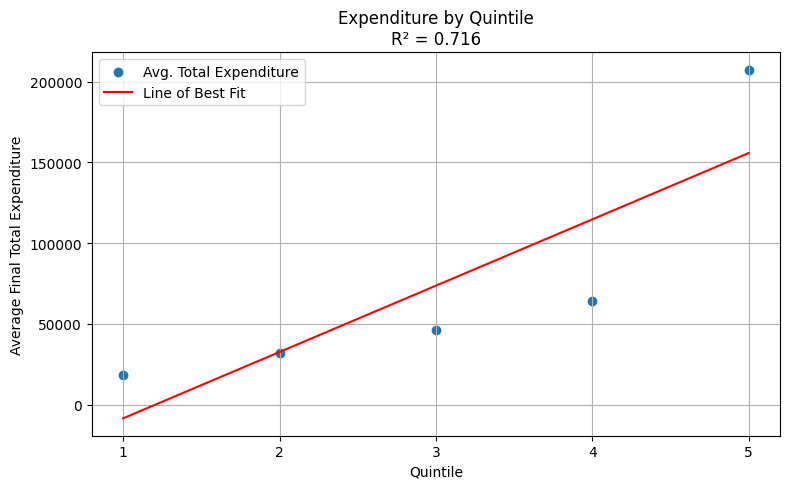

In [40]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Step 1: Map Quintile from string to numeric
aggregated_household_df['quintile_numeric'] = aggregated_household_df['Quintile'].map({
    'Q1': 1, 'Q2': 2, 'Q3': 3, 'Q4': 4, 'Q5': 5
})

# Step 2: Group by numeric quintile and get average expenditure
grouped = aggregated_household_df.groupby('quintile_numeric')['final_equivalence_expenditure'].mean().reset_index()

# Step 3: Prepare X and y
X = grouped[['quintile_numeric']]
y = grouped['final_equivalence_expenditure']

# Step 4: Fit linear regression
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

# Step 5: Calculate R²
r_squared = r2_score(y, y_pred)

# Step 6: Plot
plt.figure(figsize=(8, 5))
plt.scatter(grouped['quintile_numeric'], grouped['final_equivalence_expenditure'], label='Avg. Total Expenditure')
plt.plot(grouped['quintile_numeric'], y_pred, color='red', label='Line of Best Fit')
plt.xlabel('Quintile')
plt.ylabel('Average Final Total Expenditure')
plt.title(f'Expenditure by Quintile\nR² = {r_squared:.3f}')
plt.xticks([1, 2, 3, 4, 5])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Save the final dataframe

# Set your desired path
output_path = '/Users/gianjaeger/Desktop/Applied Machine Learning Project/Data/aggregated_household_df.pkl'

# Save the DataFrame
aggregated_household_df.to_pickle(output_path)
  
print("✅ DataFrame saved as pickle!")

✅ DataFrame saved as pickle!


----